# Machine Learning Pipeline — Dataset 1 (20k Audio)

In [1]:
import os
import time
import numpy as np
import librosa
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

In [2]:
# ============ DATASET PATHS ============
DATASET_NAME = "Dataset 1 - 20k Audio"
BASE_PATH = r"D:\Queenless\20k_audio_splitted_dataset"
FEATURE_DIR = r"D:\Queenless\features"
LABELS = ['Queen', 'NonQueen']

train_path = os.path.join(BASE_PATH, 'train')
val_path   = os.path.join(BASE_PATH, 'val')
test_path  = os.path.join(BASE_PATH, 'test')
output_dir = FEATURE_DIR
os.makedirs(output_dir, exist_ok=True)

print(f"Dataset: {DATASET_NAME}")
print(f"Labels:  {LABELS}")

Dataset: Dataset 1 - 20k Audio
Labels:  ['Queen', 'NonQueen']


In [3]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path

def report_confusion(y_true, y_pred, title, folder="confusion_matrices"):
    """Plot & save confusion matrix, print accuracy, return acc."""
    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    folder_path = Path(folder)
    folder_path.mkdir(parents=True, exist_ok=True)
    safe_title = title.lower().replace(" ", "_").replace("+", "_").replace("/", "_").replace("(", "").replace(")", "").replace(",", "")
    img_path = folder_path / f"{safe_title}.png"
    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay(cm).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(img_path, dpi=150)
    plt.show()
    plt.close(fig)
    print(f"{title} - Accuracy: {acc*100:.2f}%")
    print(f"Saved: {img_path}")
    return acc

def train_and_evaluate(clf, X_train, y_train, X_test, y_test,
                       model_name="Model", feature_name="Feature"):
    """Train a classifier, predict, show confusion matrix, return (acc, preds)."""
    start = time.time()
    clf.fit(X_train, y_train)
    elapsed = time.time() - start
    preds = clf.predict(X_test)
    title = f"{model_name} ({feature_name})"
    print(f"  Training time: {elapsed:.2f}s")
    acc = report_confusion(y_test, preds, title)
    return acc, preds

# 1. FFT (Origin)

In [4]:
# --- FFT Origin: extract raw FFT magnitude (no pre-emphasis) ---

def extract_fft_features(file_path, n_fft=512):
    """Load audio and compute raw FFT magnitude (positive freqs only)."""
    try:
        audio, sr = librosa.load(file_path, sr=None)
        fft = np.fft.fft(audio, n=n_fft)
        fft_magnitude = np.abs(fft[:n_fft // 2 + 1])  # positive frequencies (257 for n_fft=512)
        return fft_magnitude
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

def load_dataset_fft(base_path, labels):
    """Walk train/val/test splits, extract FFT features, encode labels."""
    splits = {}
    for split in ['train', 'val', 'test']:
        features, raw_labels = [], []
        for label in labels:
            folder = os.path.join(base_path, split, label)
            if not os.path.exists(folder):
                continue
            for fname in os.listdir(folder):
                if fname.endswith('.wav'):
                    feat = extract_fft_features(os.path.join(folder, fname), n_fft=512)
                    if feat is not None:
                        features.append(feat)
                        raw_labels.append(label)
        splits[split] = (np.array(features), raw_labels)

    # Encode labels with a shared LabelEncoder
    le = LabelEncoder()
    all_raw = splits['train'][1] + splits['val'][1] + splits['test'][1]
    le.fit(all_raw)

    result = {}
    for split in ['train', 'val', 'test']:
        feats, raw = splits[split]
        result[split] = (feats, le.transform(raw))
        print(f"  {split}: {feats.shape}")
    return result

print("Loading FFT Origin features...")
# IMPORTANT: Original iterates ['NonQueen', 'Queen'] (not LABELS order)
fft_data = load_dataset_fft(BASE_PATH, ['NonQueen', 'Queen'])

Loading FFT Origin features...
  train: (14066, 257)
  val: (2010, 257)
  test: (4000, 257)


In [5]:
# Merge train + val, scale
fft_train = np.vstack((fft_data['train'][0], fft_data['val'][0]))
fft_train_labels = np.hstack((fft_data['train'][1], fft_data['val'][1]))
fft_test = fft_data['test'][0]
fft_test_labels = fft_data['test'][1]

scaler_fft_origin = StandardScaler()
fft_train_scaled = scaler_fft_origin.fit_transform(fft_train)
fft_test_scaled  = scaler_fft_origin.transform(fft_test)

print(f"Train: {fft_train.shape}, Test: {fft_test.shape}")

Train: (16076, 257), Test: (4000, 257)


=== FFT Origin ===
  Training time: 0.01s


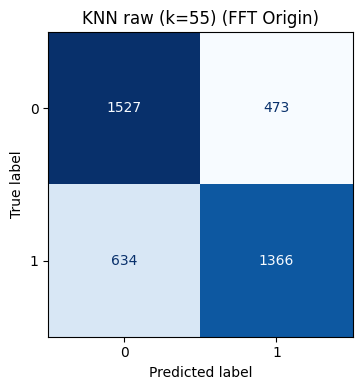

KNN raw (k=55) (FFT Origin) - Accuracy: 72.32%
Saved: confusion_matrices\knn_raw_k=55_fft_origin.png
  Training time: 0.01s


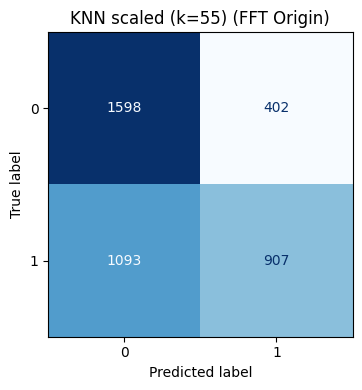

KNN scaled (k=55) (FFT Origin) - Accuracy: 62.62%
Saved: confusion_matrices\knn_scaled_k=55_fft_origin.png
  Training time: 18.64s


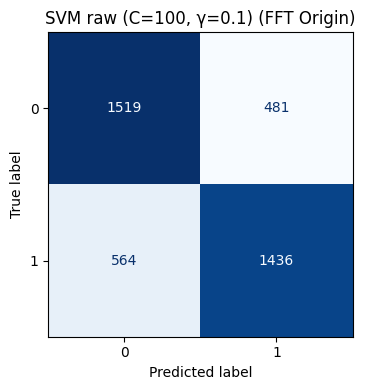

SVM raw (C=100, γ=0.1) (FFT Origin) - Accuracy: 73.88%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_fft_origin.png
  Training time: 144.72s


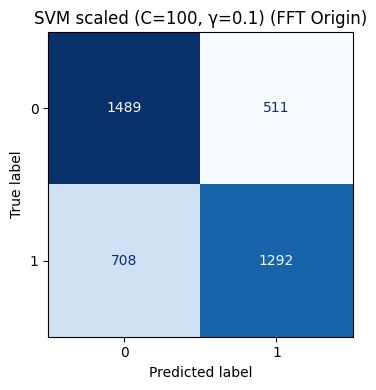

SVM scaled (C=100, γ=0.1) (FFT Origin) - Accuracy: 69.53%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_fft_origin.png
  Training time: 23.75s


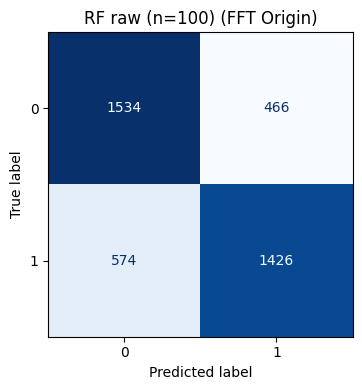

RF raw (n=100) (FFT Origin) - Accuracy: 74.00%
Saved: confusion_matrices\rf_raw_n=100_fft_origin.png
  Training time: 77.94s


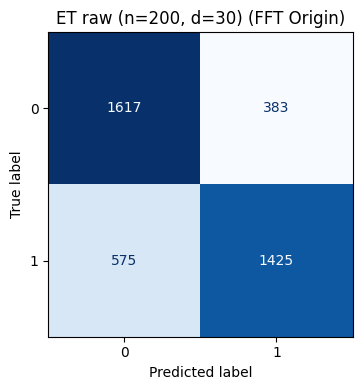

ET raw (n=200, d=30) (FFT Origin) - Accuracy: 76.05%
Saved: confusion_matrices\et_raw_n=200_d=30_fft_origin.png
  Training time: 79.81s


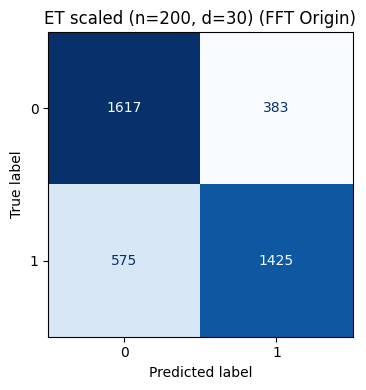

ET scaled (n=200, d=30) (FFT Origin) - Accuracy: 76.05%
Saved: confusion_matrices\et_scaled_n=200_d=30_fft_origin.png


(0.7605, array([0, 0, 0, ..., 1, 0, 1]))

In [6]:
print("=== FFT Origin ===" )

# KNN raw (k=55)
train_and_evaluate(KNeighborsClassifier(n_neighbors=55),
                   fft_train, fft_train_labels, fft_test, fft_test_labels,
                   "KNN raw (k=55)", "FFT Origin")

# KNN scaled (k=55)
train_and_evaluate(KNeighborsClassifier(n_neighbors=55),
                   fft_train_scaled, fft_train_labels, fft_test_scaled, fft_test_labels,
                   "KNN scaled (k=55)", "FFT Origin")

# SVM raw
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_train, fft_train_labels, fft_test, fft_test_labels,
                   "SVM raw (C=100, γ=0.1)", "FFT Origin")

# SVM scaled
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_train_scaled, fft_train_labels, fft_test_scaled, fft_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "FFT Origin")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2, 
                    min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
                    max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, 
                    n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None, 
                    ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                    fft_train, fft_train_labels, fft_test, fft_test_labels,
                    "RF raw (n=100)", "FFT Origin")

# ET raw
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2, min_samples_leaf=1, 
                                     min_weight_fraction_leaf=0.0, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0,
                                     bootstrap=False, oob_score=False, n_jobs=None, random_state=42, verbose=0, warm_start=False, 
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   fft_train, fft_train_labels, fft_test, fft_test_labels,
                   "ET raw (n=200, d=30)", "FFT Origin")

# ET scaled (dataset1 only)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2, min_samples_leaf=1, 
                                     min_weight_fraction_leaf=0.0, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0,
                                     bootstrap=False, oob_score=False, n_jobs=None, random_state=42, verbose=0, warm_start=False, 
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   fft_train_scaled, fft_train_labels, fft_test_scaled, fft_test_labels,
                   "ET scaled (n=200, d=30)", "FFT Origin")

# 2. FFTs (Pre-emphasis + Framing + Windowing + FFT)

In [7]:
# --- Signal processing pipeline for FFTs ---
# NOTE: These implementations are DATASET-SPECIFIC.
#   - framing() uses np.pad + float(np.abs(...)) for num_frames
#   - fft_frames() uses np.fft.fft (not rfft) with [:, :NFFT//2+1]
#   - log uses np.maximum (not addition)

def pre_emphasis(signal_in, pre_emph=0.97):
    """Boost high frequencies with first-order high-pass filter."""
    return np.append(signal_in[0], signal_in[1:] - pre_emph * signal_in[:-1])

def framing(signal_in, sample_rate, frame_size=0.025, frame_stride=0.01):
    """Split signal into overlapping frames using np.pad."""
    frame_length = int(round(frame_size * sample_rate))
    frame_step   = int(round(frame_stride * sample_rate))
    signal_length = len(signal_in)

    num_frames = int(np.ceil(float(np.abs(signal_length - frame_length)) / frame_step)) + 1

    pad_signal_length = num_frames * frame_step + frame_length
    pad_signal = np.pad(signal_in, (0, pad_signal_length - signal_length), mode='constant')

    indices = (np.arange(0, frame_length)
               + np.arange(0, num_frames * frame_step, frame_step)[:, None])
    frames = pad_signal[indices.astype(np.int32)]
    return frames

def windowing(frames):
    """Apply Hamming window to each frame."""
    frame_length = frames.shape[1]
    return frames * np.hamming(frame_length)

def fft_frames(frames, NFFT=512):
    """Compute FFT magnitude per frame (positive freqs only)."""
    # Dataset1: uses np.fft.fft then slices [:, :NFFT//2+1]
    return np.abs(np.fft.fft(frames, NFFT))[:, :NFFT // 2 + 1]

In [8]:
def compute_fft_features(signal_in, sample_rate, frame_size=0.025,
                         frame_stride=0.01, NFFT=512, apply_log=True):
    """Full pipeline: pre-emphasis → framing → windowing → FFT → mean."""
    emphasized = pre_emphasis(signal_in)
    frames = framing(emphasized, sample_rate, frame_size, frame_stride)
    windowed = windowing(frames)
    mag = fft_frames(windowed, NFFT)
    feature = np.mean(mag, axis=0)          # average across frames
    if apply_log:
        feature = np.log(np.maximum(feature, 1e-8))  # Dataset1: np.maximum
    return feature

def load_fft_features_from_directory(directory, sample_rate=22050, NFFT=512,
                                     output_dir=None, dataset_type='train'):
    """Extract or load cached FFTs features (pkl prefix: ffts3_)."""
    feat_file  = os.path.join(output_dir, f'ffts3_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'ffts3_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_fft_features(sig, sr, NFFT=NFFT))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [9]:
# Load FFTs features from each split
ffts_train, ffts_train_labels = load_fft_features_from_directory(train_path, NFFT=512, output_dir=output_dir, dataset_type='train')
ffts_val,   ffts_val_labels   = load_fft_features_from_directory(val_path,   NFFT=512, output_dir=output_dir, dataset_type='val')
ffts_test,  ffts_test_labels  = load_fft_features_from_directory(test_path,  NFFT=512, output_dir=output_dir, dataset_type='test')

# Merge train + val
ffts_train = np.vstack((ffts_train, ffts_val))
ffts_train_labels = np.hstack((ffts_train_labels, ffts_val_labels))

# Scale
scaler_ffts = StandardScaler()
ffts_train_scaled = scaler_ffts.fit_transform(ffts_train)
ffts_test_scaled  = scaler_ffts.transform(ffts_test)

print(f"FFTs — Train: {ffts_train.shape}, Test: {ffts_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs — Train: (16076, 257), Test: (4000, 257)


=== FFTs ===
  Training time: 0.01s


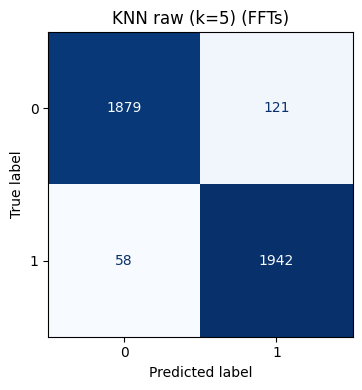

KNN raw (k=5) (FFTs) - Accuracy: 95.53%
Saved: confusion_matrices\knn_raw_k=5_ffts.png
  Training time: 0.01s


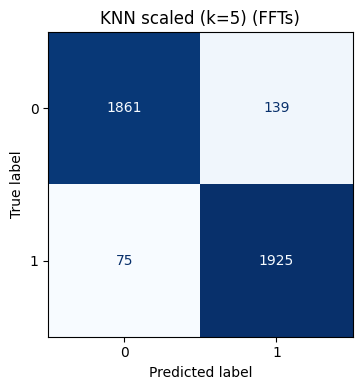

KNN scaled (k=5) (FFTs) - Accuracy: 94.65%
Saved: confusion_matrices\knn_scaled_k=5_ffts.png
  Training time: 4.73s


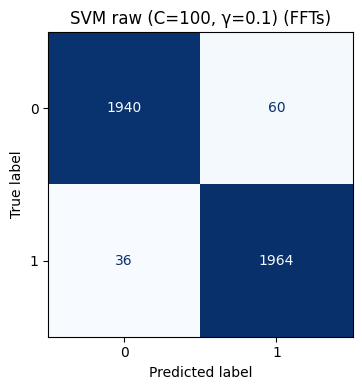

SVM raw (C=100, γ=0.1) (FFTs) - Accuracy: 97.60%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_ffts.png
  Training time: 26.29s


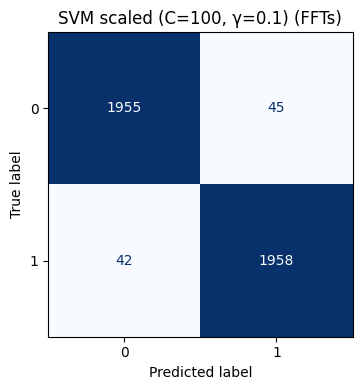

SVM scaled (C=100, γ=0.1) (FFTs) - Accuracy: 97.82%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_ffts.png
  Training time: 18.97s


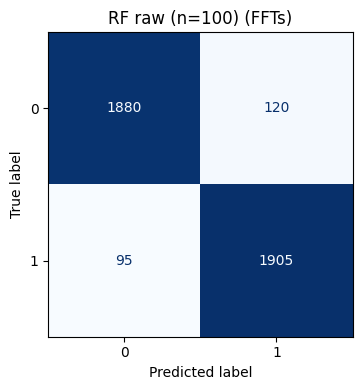

RF raw (n=100) (FFTs) - Accuracy: 94.62%
Saved: confusion_matrices\rf_raw_n=100_ffts.png
  Training time: 5.86s


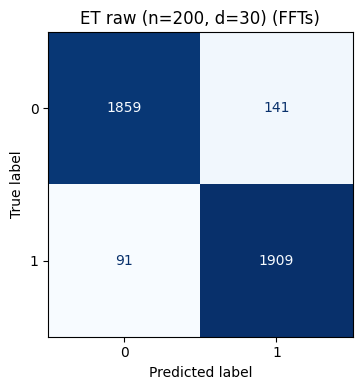

ET raw (n=200, d=30) (FFTs) - Accuracy: 94.20%
Saved: confusion_matrices\et_raw_n=200_d=30_ffts.png
  Training time: 5.89s


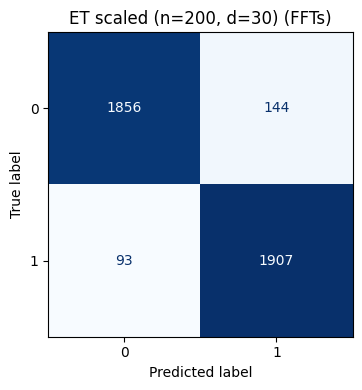

ET scaled (n=200, d=30) (FFTs) - Accuracy: 94.08%
Saved: confusion_matrices\et_scaled_n=200_d=30_ffts.png


(0.94075,
 array(['Queen', 'Queen', 'Queen', ..., 'NonQueen', 'NonQueen', 'NonQueen'],
       dtype='<U8'))

In [10]:
print("=== FFTs ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "KNN raw (k=5)", "FFTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_train_scaled, ffts_train_labels, ffts_test_scaled, ffts_test_labels,
                   "KNN scaled (k=5)", "FFTs")

# SVM raw
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "SVM raw (C=100, γ=0.1)", "FFTs")

# SVM scaled
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   ffts_train_scaled, ffts_train_labels, ffts_test_scaled, ffts_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "FFTs")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "RF raw (n=100)", "FFTs")

# ET raw
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "ET raw (n=200, d=30)", "FFTs")

# ET scaled (dataset1 only)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   ffts_train_scaled, ffts_train_labels, ffts_test_scaled, ffts_test_labels,
                   "ET scaled (n=200, d=30)", "FFTs")

# 3. STFT

In [11]:
# --- STFT: librosa-based short-time Fourier transform ---

def compute_stft_features(signal_in, sample_rate, n_fft=2048, hop_length=512,
                          apply_log=True):
    """Compute STFT magnitude, average over time axis."""
    stft_matrix = np.abs(librosa.stft(signal_in, n_fft=n_fft, hop_length=hop_length))
    if apply_log:
        stft_matrix = np.log(stft_matrix + 1e-8)
    return np.mean(stft_matrix, axis=1)   # → shape (n_fft//2+1,)

def load_stft_features_from_directory(directory, sample_rate=22050,
                                      n_fft=2048, hop_length=512,
                                      output_dir=None, dataset_type='train'):
    """Extract or load cached STFT features (pkl prefix: stft2_)."""
    feat_file  = os.path.join(output_dir, f'stft2_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'stft2_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_stft_features(sig, sr, n_fft=n_fft,
                                                  hop_length=hop_length))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [12]:
# Load STFT features (n_fft=4096, hop_length=1024)
stft_train, stft_train_labels = load_stft_features_from_directory(train_path, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='train')
stft_val,   stft_val_labels   = load_stft_features_from_directory(val_path,   n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='val')
stft_test,  stft_test_labels  = load_stft_features_from_directory(test_path,  n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='test')

stft_train = np.vstack((stft_train, stft_val))
stft_train_labels = np.hstack((stft_train_labels, stft_val_labels))

scaler_stft = StandardScaler()
stft_train_scaled = scaler_stft.fit_transform(stft_train)
stft_test_scaled  = scaler_stft.transform(stft_test)

print(f"STFT — Train: {stft_train.shape}, Test: {stft_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
STFT — Train: (16076, 2049), Test: (4000, 2049)


=== STFT ===
  Training time: 0.04s


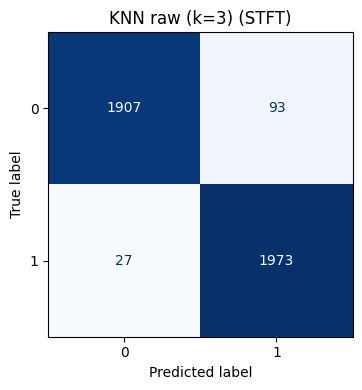

KNN raw (k=3) (STFT) - Accuracy: 97.00%
Saved: confusion_matrices\knn_raw_k=3_stft.png
  Training time: 0.04s


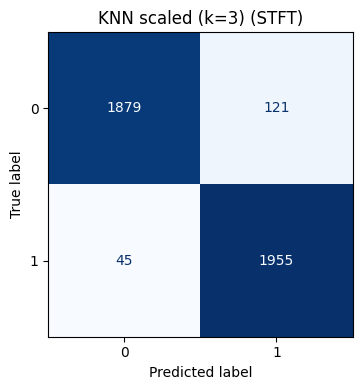

KNN scaled (k=3) (STFT) - Accuracy: 95.85%
Saved: confusion_matrices\knn_scaled_k=3_stft.png
  Training time: 107.36s


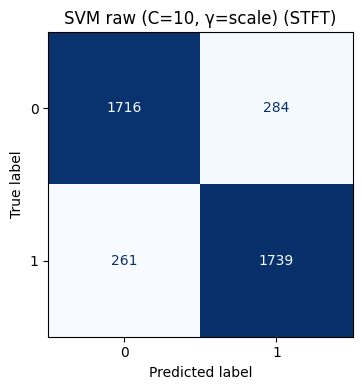

SVM raw (C=10, γ=scale) (STFT) - Accuracy: 86.38%
Saved: confusion_matrices\svm_raw_c=10_γ=scale_stft.png


(0.86375,
 array(['Queen', 'Queen', 'Queen', ..., 'NonQueen', 'NonQueen', 'NonQueen'],
       dtype='<U8'))

In [13]:
print("=== STFT ===")

# KNN raw (k=3) — dataset1 uses k=3
train_and_evaluate(KNeighborsClassifier(n_neighbors=3),
                   stft_train, stft_train_labels, stft_test, stft_test_labels,
                   "KNN raw (k=3)", "STFT")

# KNN scaled (k=3)
train_and_evaluate(KNeighborsClassifier(n_neighbors=3),
                   stft_train_scaled, stft_train_labels, stft_test_scaled, stft_test_labels,
                   "KNN scaled (k=3)", "STFT")

# SVM raw (C=10, γ=scale) — note: γ='scale', NOT 0.1
train_and_evaluate(SVC(C=10, kernel='rbf', gamma='scale', random_state=42),
                   stft_train, stft_train_labels, stft_test, stft_test_labels,
                   "SVM raw (C=10, γ=scale)", "STFT")

# NOTE: Dataset1 does NOT train RF or ET on STFT

# 4. FFTs + STFT

In [14]:
# --- FFTs + STFT: scale each type SEPARATELY then concatenate ---
# This is DATASET-SPECIFIC: Dataset1 scales individually, Dataset2 scales after concat.

scaler_fft_for_combo = StandardScaler()
fft_train_sc = scaler_fft_for_combo.fit_transform(ffts_train)
fft_test_sc  = scaler_fft_for_combo.transform(ffts_test)

scaler_stft_for_combo = StandardScaler()
stft_train_sc = scaler_stft_for_combo.fit_transform(stft_train)
stft_test_sc  = scaler_stft_for_combo.transform(stft_test)

# Scaled version (scale separately → concat)
fft_stft_train_scaled = np.concatenate([fft_train_sc, stft_train_sc], axis=1)
fft_stft_test_scaled  = np.concatenate([fft_test_sc,  stft_test_sc],  axis=1)

# Raw version (concat without scaling)
fft_stft_train_raw = np.concatenate([ffts_train, stft_train], axis=1)
fft_stft_test_raw  = np.concatenate([ffts_test,  stft_test],  axis=1)

# Use ffts labels (same as stft labels)
fft_stft_train_labels = ffts_train_labels
fft_stft_test_labels  = ffts_test_labels

print(f"FFTs+STFT scaled — Train: {fft_stft_train_scaled.shape}")
print(f"FFTs+STFT raw    — Train: {fft_stft_train_raw.shape}")

FFTs+STFT scaled — Train: (16076, 2306)
FFTs+STFT raw    — Train: (16076, 2306)


=== FFTs + STFT ===
  Training time: 0.05s


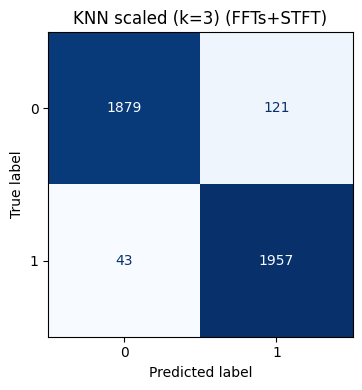

KNN scaled (k=3) (FFTs+STFT) - Accuracy: 95.90%
Saved: confusion_matrices\knn_scaled_k=3_ffts_stft.png
  Training time: 0.05s


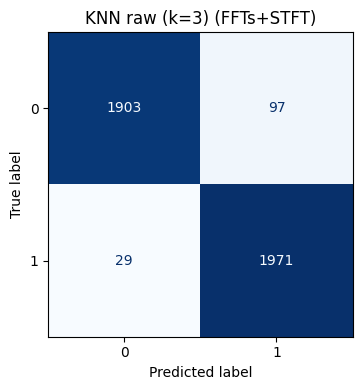

KNN raw (k=3) (FFTs+STFT) - Accuracy: 96.85%
Saved: confusion_matrices\knn_raw_k=3_ffts_stft.png
  Training time: 1145.86s


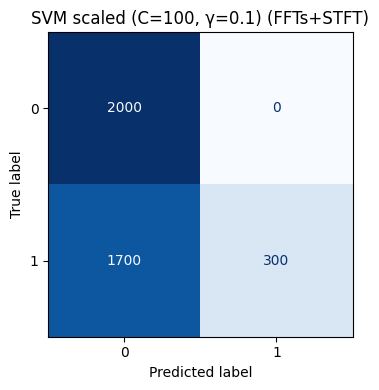

SVM scaled (C=100, γ=0.1) (FFTs+STFT) - Accuracy: 57.50%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_ffts_stft.png
  Training time: 748.57s


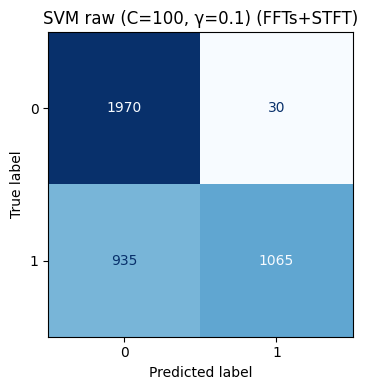

SVM raw (C=100, γ=0.1) (FFTs+STFT) - Accuracy: 75.88%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_ffts_stft.png
  Training time: 80.51s


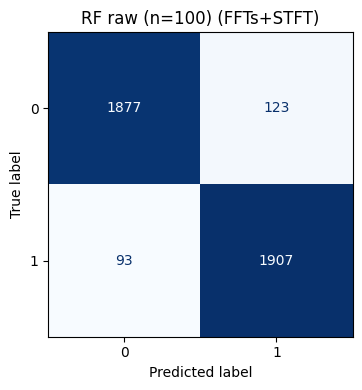

RF raw (n=100) (FFTs+STFT) - Accuracy: 94.60%
Saved: confusion_matrices\rf_raw_n=100_ffts_stft.png
  Training time: 18.49s


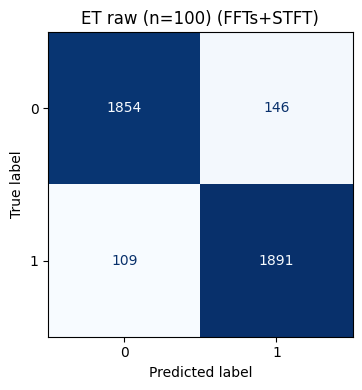

ET raw (n=100) (FFTs+STFT) - Accuracy: 93.62%
Saved: confusion_matrices\et_raw_n=100_ffts_stft.png


(0.93625,
 array(['Queen', 'Queen', 'Queen', ..., 'NonQueen', 'NonQueen', 'NonQueen'],
       dtype='<U8'))

In [15]:
print("=== FFTs + STFT ===")

# KNN scaled (k=3)
train_and_evaluate(KNeighborsClassifier(n_neighbors=3),
                   fft_stft_train_scaled, fft_stft_train_labels,
                   fft_stft_test_scaled,  fft_stft_test_labels,
                   "KNN scaled (k=3)", "FFTs+STFT")

# KNN raw (k=3)
train_and_evaluate(KNeighborsClassifier(n_neighbors=3),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "KNN raw (k=3)", "FFTs+STFT")

# SVM scaled
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_stft_train_scaled, fft_stft_train_labels,
                   fft_stft_test_scaled,  fft_stft_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "FFTs+STFT")

# SVM raw
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "SVM raw (C=100, γ=0.1)", "FFTs+STFT")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "RF raw (n=100)", "FFTs+STFT")

# ET raw (n=100 for dataset1, NOT 200)
train_and_evaluate(ExtraTreesClassifier(n_estimators=100, random_state=42),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "ET raw (n=100)", "FFTs+STFT")

# 5. STFTs (Pre-emphasis + STFT per frame)

In [16]:
# --- STFTs: Pre-emphasis → Framing → Windowing → STFT per frame ---
# Dataset1 uses MODULAR approach: calls separate functions.
# (pre_emphasis, framing, windowing are already defined in FFTs section)

def compute_stfts_features(signal_in, sample_rate, frame_size=0.025,
                           frame_stride=0.01, n_fft=4096, apply_log=True):
    """Apply pre-emphasis → framing → windowing → STFT per frame → average."""
    emphasized = pre_emphasis(signal_in)
    frames = framing(emphasized, sample_rate, frame_size, frame_stride)
    windowed = windowing(frames)

    # Compute STFT for each frame (take first column = DC to Nyquist)
    mag_frames = []
    for frame in windowed:
        stft = np.abs(librosa.stft(frame, n_fft=n_fft))
        mag_frames.append(stft[:, 0])   # first time column of each frame's STFT

    mag_frames = np.array(mag_frames)
    feature = np.mean(mag_frames, axis=0)   # average across frames

    if apply_log:
        feature = np.log(np.maximum(feature, 1e-8))
    return feature

def load_stfts_features_from_directory(directory, sample_rate=22050, n_fft=4096,
                                       frame_size=0.025, frame_stride=0.01,
                                       output_dir=None, dataset_type='train'):
    """Extract or load cached STFTs features (pkl prefix: stfts1_)."""
    feat_file  = os.path.join(output_dir, f'stfts1_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'stfts1_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_stfts_features(sig, sr, frame_size=frame_size,
                                                   frame_stride=frame_stride, n_fft=n_fft))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [17]:
stfts_train, stfts_train_labels = load_stfts_features_from_directory(train_path, n_fft=4096, output_dir=output_dir, dataset_type='train')
stfts_val,   stfts_val_labels   = load_stfts_features_from_directory(val_path,   n_fft=4096, output_dir=output_dir, dataset_type='val')
stfts_test,  stfts_test_labels  = load_stfts_features_from_directory(test_path,  n_fft=4096, output_dir=output_dir, dataset_type='test')

stfts_train = np.vstack((stfts_train, stfts_val))
stfts_train_labels = np.hstack((stfts_train_labels, stfts_val_labels))

scaler_stfts = StandardScaler()
stfts_train_scaled = scaler_stfts.fit_transform(stfts_train)
stfts_test_scaled  = scaler_stfts.transform(stfts_test)

print(f"STFTs — Train: {stfts_train.shape}, Test: {stfts_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
STFTs — Train: (16076, 2049), Test: (4000, 2049)


=== STFTs ===
  Training time: 0.05s


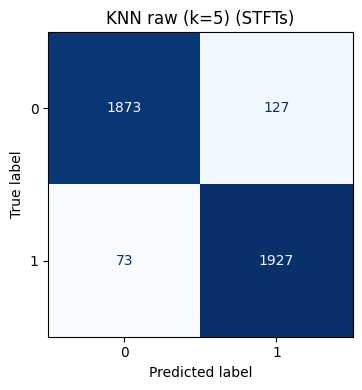

KNN raw (k=5) (STFTs) - Accuracy: 95.00%
Saved: confusion_matrices\knn_raw_k=5_stfts.png
  Training time: 0.04s


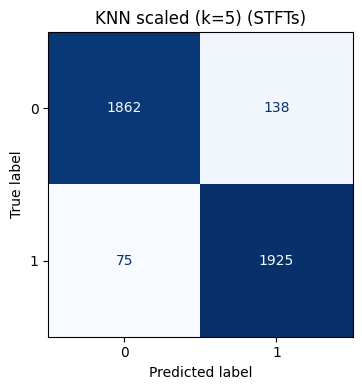

KNN scaled (k=5) (STFTs) - Accuracy: 94.67%
Saved: confusion_matrices\knn_scaled_k=5_stfts.png
  Training time: 537.57s


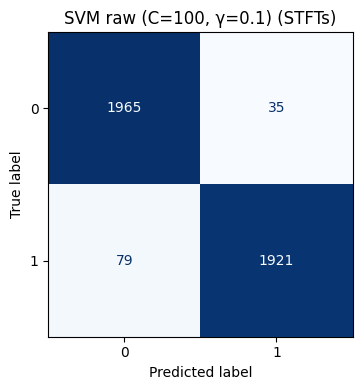

SVM raw (C=100, γ=0.1) (STFTs) - Accuracy: 97.15%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_stfts.png
  Training time: 830.66s


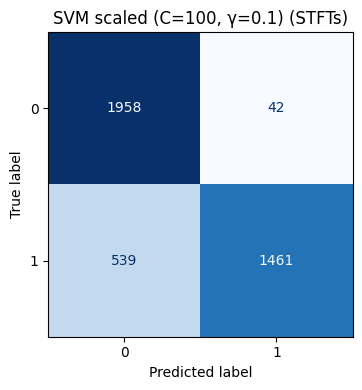

SVM scaled (C=100, γ=0.1) (STFTs) - Accuracy: 85.47%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_stfts.png
  Training time: 67.47s


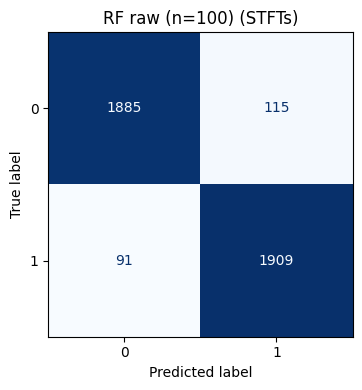

RF raw (n=100) (STFTs) - Accuracy: 94.85%
Saved: confusion_matrices\rf_raw_n=100_stfts.png
  Training time: 34.76s


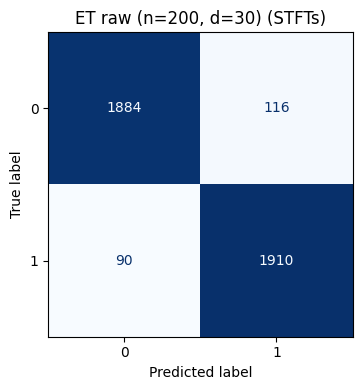

ET raw (n=200, d=30) (STFTs) - Accuracy: 94.85%
Saved: confusion_matrices\et_raw_n=200_d=30_stfts.png


(0.9485,
 array(['Queen', 'Queen', 'Queen', ..., 'NonQueen', 'NonQueen', 'NonQueen'],
       dtype='<U8'))

In [18]:
print("=== STFTs ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "KNN raw (k=5)", "STFTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   stfts_train_scaled, stfts_train_labels, stfts_test_scaled, stfts_test_labels,
                   "KNN scaled (k=5)", "STFTs")

# SVM raw (C=100, γ=0.1) — dataset1 specific
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "SVM raw (C=100, γ=0.1)", "STFTs")

# SVM scaled (dataset1 only — trains SVM on scaled STFTs)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   stfts_train_scaled, stfts_train_labels, stfts_test_scaled, stfts_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "STFTs")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "RF raw (n=100)", "STFTs")

# ET raw
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "ET raw (n=200, d=30)", "STFTs")

# 6. FFTs + STFTs

In [19]:
# --- Combine FFTs + STFTs ---
ffts_stfts_train = np.hstack((ffts_train, stfts_train))
ffts_stfts_test  = np.hstack((ffts_test,  stfts_test))

scaler_ffts_stfts = StandardScaler()
ffts_stfts_train_scaled = scaler_ffts_stfts.fit_transform(ffts_stfts_train)
ffts_stfts_test_scaled  = scaler_ffts_stfts.transform(ffts_stfts_test)

# Use ffts labels (both come from same audio files)
ffts_stfts_labels_train = ffts_train_labels
ffts_stfts_labels_test  = ffts_test_labels

print(f"FFTs+STFTs — Train: {ffts_stfts_train.shape}, Test: {ffts_stfts_test.shape}")

FFTs+STFTs — Train: (16076, 2306), Test: (4000, 2306)


=== FFTs + STFTs ===
  Training time: 0.06s


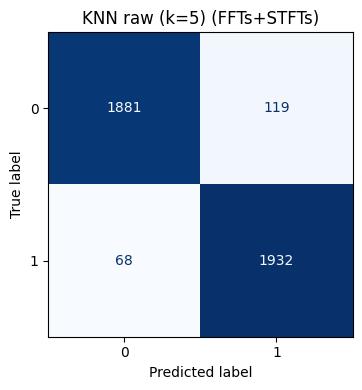

KNN raw (k=5) (FFTs+STFTs) - Accuracy: 95.33%
Saved: confusion_matrices\knn_raw_k=5_ffts_stfts.png
  Training time: 0.05s


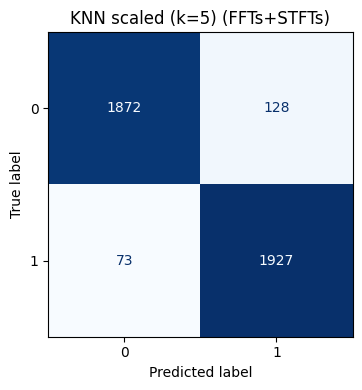

KNN scaled (k=5) (FFTs+STFTs) - Accuracy: 94.97%
Saved: confusion_matrices\knn_scaled_k=5_ffts_stfts.png
  Training time: 719.62s


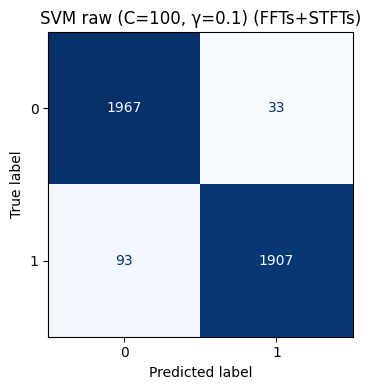

SVM raw (C=100, γ=0.1) (FFTs+STFTs) - Accuracy: 96.85%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_ffts_stfts.png
  Training time: 921.74s


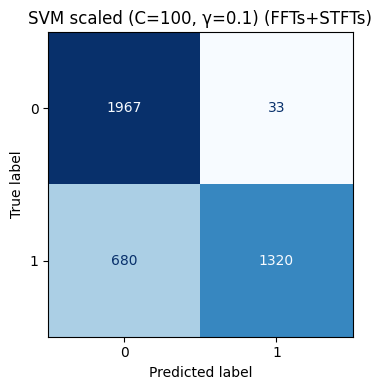

SVM scaled (C=100, γ=0.1) (FFTs+STFTs) - Accuracy: 82.17%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_ffts_stfts.png
  Training time: 79.24s


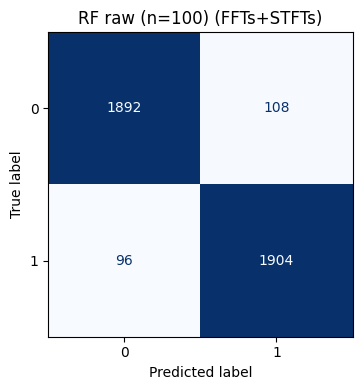

RF raw (n=100) (FFTs+STFTs) - Accuracy: 94.90%
Saved: confusion_matrices\rf_raw_n=100_ffts_stfts.png
  Training time: 38.12s


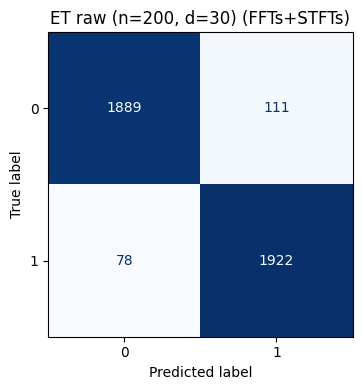

ET raw (n=200, d=30) (FFTs+STFTs) - Accuracy: 95.28%
Saved: confusion_matrices\et_raw_n=200_d=30_ffts_stfts.png


(0.95275,
 array(['Queen', 'Queen', 'Queen', ..., 'NonQueen', 'NonQueen', 'NonQueen'],
       dtype='<U8'))

In [20]:
print("=== FFTs + STFTs ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "KNN raw (k=5)", "FFTs+STFTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_stfts_train_scaled, ffts_stfts_labels_train,
                   ffts_stfts_test_scaled,  ffts_stfts_labels_test,
                   "KNN scaled (k=5)", "FFTs+STFTs")

# SVM raw (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "SVM raw (C=100, γ=0.1)", "FFTs+STFTs")

# SVM scaled (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   ffts_stfts_train_scaled, ffts_stfts_labels_train,
                   ffts_stfts_test_scaled,  ffts_stfts_labels_test,
                   "SVM scaled (C=100, γ=0.1)", "FFTs+STFTs")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "RF raw (n=100)", "FFTs+STFTs")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "ET raw (n=200, d=30)", "FFTs+STFTs")

# 7. CQT

In [21]:
# --- CQT: Constant-Q Transform (no pre-emphasis) ---

def compute_cqt_features(signal_in, sample_rate, hop_length=512, fmin=None,
                         n_bins=84, bins_per_octave=12, apply_log=True):
    """Compute CQT magnitude → log → average over time → shape (n_bins,)."""
    cqt_matrix = np.abs(librosa.cqt(signal_in, sr=sample_rate, hop_length=hop_length,
                                    fmin=fmin, n_bins=n_bins,
                                    bins_per_octave=bins_per_octave))
    if apply_log:
        cqt_matrix = np.log(cqt_matrix + 1e-8)
    return np.mean(cqt_matrix, axis=1)

def load_cqt_features_from_directory(directory, sample_rate=22050, hop_length=512,
                                     fmin=None, n_bins=84, bins_per_octave=12,
                                     output_dir=None, dataset_type='train'):
    """Extract or load cached CQT features (pkl prefix: cqt_)."""
    feat_file  = os.path.join(output_dir, f'cqt_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'cqt_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_cqt_features(sig, sr, hop_length=hop_length,
                                                 fmin=fmin, n_bins=n_bins,
                                                 bins_per_octave=bins_per_octave))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [22]:
cqt_train, cqt_train_labels = load_cqt_features_from_directory(train_path, hop_length=512, n_bins=84, output_dir=output_dir, dataset_type='train')
cqt_val,   cqt_val_labels   = load_cqt_features_from_directory(val_path,   hop_length=512, n_bins=84, output_dir=output_dir, dataset_type='val')
cqt_test,  cqt_test_labels  = load_cqt_features_from_directory(test_path,  hop_length=512, n_bins=84, output_dir=output_dir, dataset_type='test')

cqt_train = np.vstack((cqt_train, cqt_val))
cqt_train_labels = np.hstack((cqt_train_labels, cqt_val_labels))

scaler_cqt = StandardScaler()
cqt_train_scaled = scaler_cqt.fit_transform(cqt_train)
cqt_test_scaled  = scaler_cqt.transform(cqt_test)

print(f"CQT — Train: {cqt_train.shape}, Test: {cqt_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
CQT — Train: (16076, 84), Test: (4000, 84)


=== CQT ===


  Training time: 0.01s


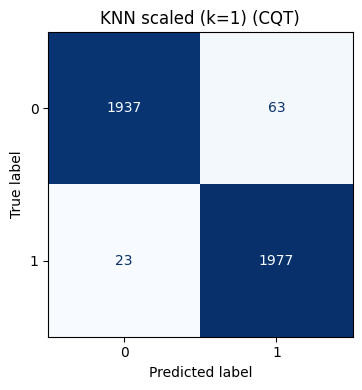

KNN scaled (k=1) (CQT) - Accuracy: 97.85%
Saved: confusion_matrices\knn_scaled_k=1_cqt.png
  Training time: 3.93s


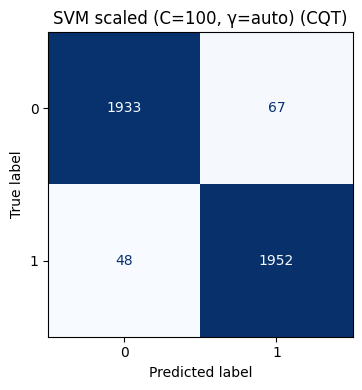

SVM scaled (C=100, γ=auto) (CQT) - Accuracy: 97.12%
Saved: confusion_matrices\svm_scaled_c=100_γ=auto_cqt.png
  Training time: 0.17s


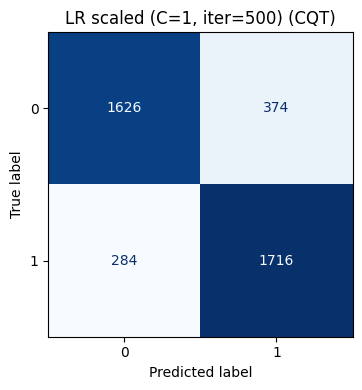

LR scaled (C=1, iter=500) (CQT) - Accuracy: 83.55%
Saved: confusion_matrices\lr_scaled_c=1_iter=500_cqt.png
  Training time: 25.76s


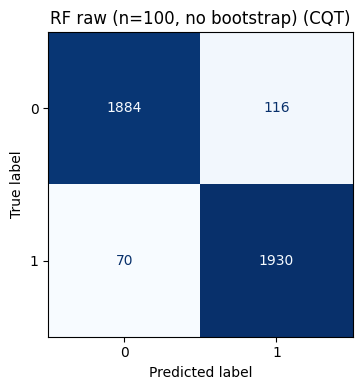

RF raw (n=100, no bootstrap) (CQT) - Accuracy: 95.35%
Saved: confusion_matrices\rf_raw_n=100_no_bootstrap_cqt.png
  Training time: 6.48s


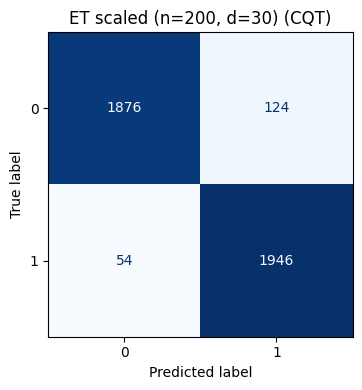

ET scaled (n=200, d=30) (CQT) - Accuracy: 95.55%
Saved: confusion_matrices\et_scaled_n=200_d=30_cqt.png


(0.9555,
 array(['Queen', 'Queen', 'Queen', ..., 'NonQueen', 'NonQueen', 'NonQueen'],
       dtype='<U8'))

In [23]:
print("=== CQT ===")

# KNN scaled (k=1) — dataset1 uses k=1, scaled only
train_and_evaluate(KNeighborsClassifier(n_neighbors=1),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "KNN scaled (k=1)", "CQT")

# SVM scaled (C=100, γ=auto) — dataset1 trains SVM on scaled only (no raw SVM)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma='auto', random_state=42),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "SVM scaled (C=100, γ=auto)", "CQT")

# LR scaled (C=1, iter=500)
train_and_evaluate(LogisticRegression(C=1.0, max_iter=500, solver='lbfgs', random_state=None),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "LR scaled (C=1, iter=500)", "CQT")

# RF raw (bootstrap=False)
train_and_evaluate(RandomForestClassifier(n_estimators=100, bootstrap=False, random_state=42),
                   cqt_train, cqt_train_labels, cqt_test, cqt_test_labels,
                   "RF raw (n=100, no bootstrap)", "CQT")

# ET scaled (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "ET scaled (n=200, d=30)", "CQT")

# 8. CQTs (Pre-emphasis + CQT)

In [24]:
# --- CQTs: Pre-emphasis + CQT ---
# (pre_emphasis already defined above)

def compute_cqts_features(signal_in, sample_rate, frame_size=0.025,
                          frame_stride=0.01, fmin=None, n_bins=84,
                          bins_per_octave=12, apply_log=True):
    """Pre-emphasis → CQT on full signal → average over time."""
    emphasized = pre_emphasis(signal_in)
    cqt_matrix = np.abs(librosa.cqt(emphasized, sr=sample_rate,
                                    fmin=fmin, n_bins=n_bins,
                                    bins_per_octave=bins_per_octave,
                                    hop_length=512))
    feature = np.mean(cqt_matrix, axis=1)
    if apply_log:
        feature = np.log(np.maximum(feature, 1e-8))
    return feature

def load_cqts_features_from_directory(directory, sample_rate=22050,
                                      frame_size=0.025, frame_stride=0.01,
                                      fmin=None, n_bins=84, bins_per_octave=12,
                                      output_dir=None, dataset_type='train'):
    """Extract or load cached CQTs features (pkl prefix: cqts_)."""
    feat_file  = os.path.join(output_dir, f'cqts_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'cqts_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_cqts_features(sig, sr, frame_size=frame_size,
                                                  frame_stride=frame_stride, fmin=fmin,
                                                  n_bins=n_bins, bins_per_octave=bins_per_octave))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [25]:
cqts_train, cqts_train_labels = load_cqts_features_from_directory(train_path, n_bins=84, output_dir=output_dir, dataset_type='train')
cqts_val,   cqts_val_labels   = load_cqts_features_from_directory(val_path,   n_bins=84, output_dir=output_dir, dataset_type='val')
cqts_test,  cqts_test_labels  = load_cqts_features_from_directory(test_path,  n_bins=84, output_dir=output_dir, dataset_type='test')

cqts_train = np.vstack((cqts_train, cqts_val))
cqts_train_labels = np.hstack((cqts_train_labels, cqts_val_labels))

scaler_cqts = StandardScaler()
cqts_train_scaled = scaler_cqts.fit_transform(cqts_train)
cqts_test_scaled  = scaler_cqts.transform(cqts_test)

print(f"CQTs — Train: {cqts_train.shape}, Test: {cqts_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
CQTs — Train: (16076, 84), Test: (4000, 84)


=== CQTs ===
  Training time: 0.01s


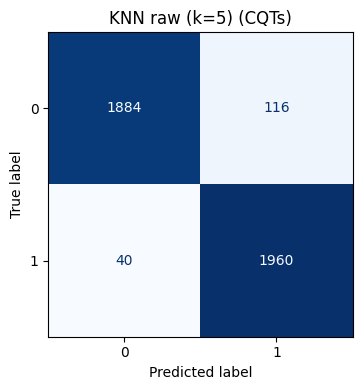

KNN raw (k=5) (CQTs) - Accuracy: 96.10%
Saved: confusion_matrices\knn_raw_k=5_cqts.png
  Training time: 0.01s


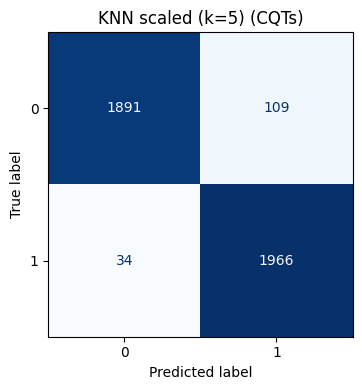

KNN scaled (k=5) (CQTs) - Accuracy: 96.43%
Saved: confusion_matrices\knn_scaled_k=5_cqts.png
  Training time: 6.71s


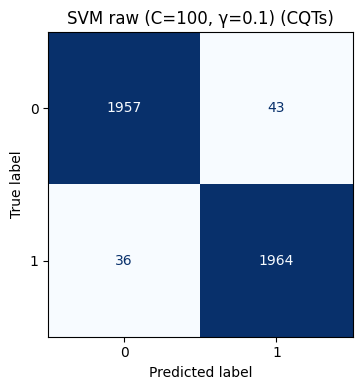

SVM raw (C=100, γ=0.1) (CQTs) - Accuracy: 98.02%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_cqts.png
  Training time: 13.83s


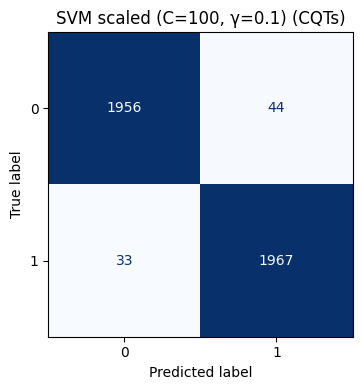

SVM scaled (C=100, γ=0.1) (CQTs) - Accuracy: 98.08%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_cqts.png
  Training time: 15.72s


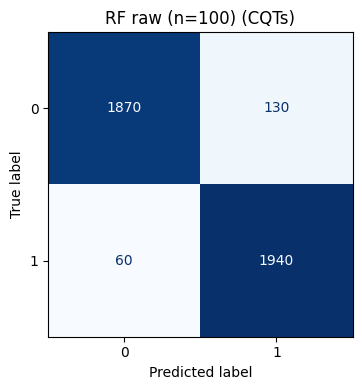

RF raw (n=100) (CQTs) - Accuracy: 95.25%
Saved: confusion_matrices\rf_raw_n=100_cqts.png
  Training time: 5.98s


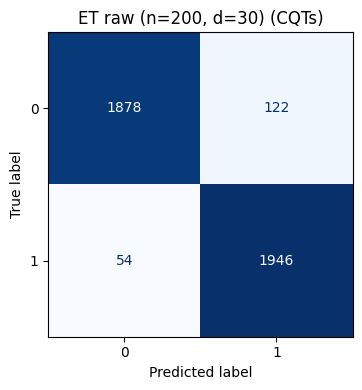

ET raw (n=200, d=30) (CQTs) - Accuracy: 95.60%
Saved: confusion_matrices\et_raw_n=200_d=30_cqts.png


(0.956,
 array(['Queen', 'Queen', 'Queen', ..., 'NonQueen', 'NonQueen', 'NonQueen'],
       dtype='<U8'))

In [26]:
print("=== CQTs ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "KNN raw (k=5)", "CQTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   cqts_train_scaled, cqts_train_labels, cqts_test_scaled, cqts_test_labels,
                   "KNN scaled (k=5)", "CQTs")

# SVM raw (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "SVM raw (C=100, γ=0.1)", "CQTs")

# SVM scaled (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   cqts_train_scaled, cqts_train_labels, cqts_test_scaled, cqts_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "CQTs")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "RF raw (n=100)", "CQTs")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "ET raw (n=200, d=30)", "CQTs")

# 9. FFTs + CQT (Combined Feature Extraction)

In [27]:
# --- FFTs+CQT: DIFFERENT signal processing from Section 2 ---
# This section redefines framing/fft to match the original combined pipeline:
#   - framing: np.zeros + np.append + np.tile (NOT np.pad)
#   - fft_frames: np.fft.rfft (NOT np.fft.fft)
#   - log: fft_feature + 1e-8 (NOT np.maximum)
#   - NFFT = 512 → feature dim = 257 (FFT) + 96 (CQT) = 353

def pre_emphasis_combined(signal_in, pre_emph=0.97):
    """Pre-emphasis filter (same as other sections)."""
    return np.append(signal_in[0], signal_in[1:] - pre_emph * signal_in[:-1])

def framing_combined(signal_in, sample_rate, frame_size=0.025, frame_stride=0.01):
    """Framing using np.zeros/np.append/np.tile approach."""
    frame_length = int(round(frame_size * sample_rate))
    frame_step   = int(round(frame_stride * sample_rate))
    signal_length = len(signal_in)
    num_frames = int(np.ceil(np.abs(signal_length - frame_length) / frame_step)) + 1

    pad_signal_length = num_frames * frame_step + frame_length
    z = np.zeros((pad_signal_length - signal_length))
    pad_signal = np.append(signal_in, z)

    indices = (np.tile(np.arange(0, frame_length), (num_frames, 1))
               + np.tile(np.arange(0, num_frames * frame_step, frame_step),
                         (frame_length, 1)).T)
    frames = pad_signal[indices.astype(np.int32, copy=False)]
    return frames

def windowing_combined(frames):
    """Hamming window (same as other sections)."""
    frame_length = frames.shape[1]
    return frames * np.hamming(frame_length)

def fft_frames_combined(frames, NFFT=512):
    """FFT using np.fft.rfft (NOT fft+slice like Section 2)."""
    return np.absolute(np.fft.rfft(frames, NFFT))

def compute_fft_features_combined(signal_in, sample_rate, frame_size=0.025,
                                  frame_stride=0.01, NFFT=512, apply_log=True):
    """Full FFT pipeline for combined extraction."""
    emphasized = pre_emphasis_combined(signal_in)
    frames = framing_combined(emphasized, sample_rate, frame_size, frame_stride)
    windowed = windowing_combined(frames)
    mag = fft_frames_combined(windowed, NFFT)
    feature = np.mean(mag, axis=0)
    if apply_log:
        feature = np.log(feature + 1e-8)   # Dataset1 FFTs+CQT: addition (not np.maximum)
    return feature

def compute_cqt_features_combined(signal_in, sample_rate, fmin=None,
                                  n_bins=84, bins_per_octave=12, apply_log=True):
    """CQT feature extraction (NO hop_length param version)."""
    cqt_matrix = np.abs(librosa.cqt(signal_in, sr=sample_rate,
                                    fmin=fmin, n_bins=n_bins,
                                    bins_per_octave=bins_per_octave))
    feature = np.mean(cqt_matrix, axis=1)
    if apply_log:
        feature = np.log(feature + 1e-8)
    return feature

def compute_combined_features(signal_in, sample_rate, frame_size=0.025,
                              NFFT=512, fmin=None, n_bins=84,
                              bins_per_octave=12, apply_log=True):
    """Compute FFT + CQT and concatenate into single vector."""
    fft_feat = compute_fft_features_combined(signal_in, sample_rate,
                                            frame_size=frame_size, NFFT=NFFT,
                                            apply_log=apply_log)
    cqt_feat = compute_cqt_features_combined(signal_in, sample_rate,
                                            fmin=fmin, n_bins=n_bins,
                                            bins_per_octave=bins_per_octave,
                                            apply_log=apply_log)
    return np.concatenate((fft_feat, cqt_feat))

In [28]:
def load_combined_features_from_directory(directory, sample_rate=22050, NFFT=512,
                                         frame_size=0.025, fmin=None, n_bins=84,
                                         bins_per_octave=12, output_dir=None,
                                         dataset_type='train'):
    """Extract or load cached FFTs+CQT features.
    PKL prefix: combined_features2_{split}_nfft{NFFT}_bins{n_bins}.pkl"""
    feat_file  = os.path.join(output_dir, f'combined_features2_{dataset_type}_nfft{NFFT}_bins{n_bins}.pkl')
    label_file = os.path.join(output_dir, f'combined_labels2_{dataset_type}_nfft{NFFT}_bins{n_bins}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in ['NonQueen', 'Queen']:   # Note: order is NonQueen, Queen here
        folder = os.path.join(directory, label)
        if not os.path.exists(folder):
            print(f"  Warning: {folder} not found, skipping")
            continue
        for fname in os.listdir(folder):
            if not fname.endswith(('.wav', '.mp3', '.flac', '.ogg')):
                continue
            fpath = os.path.join(folder, fname)
            try:
                sig, sr = librosa.load(fpath, sr=sample_rate)
                feat = compute_combined_features(sig, sr, frame_size=frame_size,
                                                NFFT=NFFT, fmin=fmin, n_bins=n_bins,
                                                bins_per_octave=bins_per_octave)
                features.append(feat)
                labels.append(label)
            except Exception as e:
                print(f"  Error: {fpath}: {e}")
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s — shape {features.shape}")
    return features, labels

In [29]:
# Load combined FFTs+CQT features (NFFT=512, n_bins=96)
combined_train, combined_train_labels = load_combined_features_from_directory(
    train_path, NFFT=512, n_bins=96, output_dir=output_dir, dataset_type='train')
combined_val, combined_val_labels = load_combined_features_from_directory(
    val_path, NFFT=512, n_bins=96, output_dir=output_dir, dataset_type='val')
combined_test, combined_test_labels = load_combined_features_from_directory(
    test_path, NFFT=512, n_bins=96, output_dir=output_dir, dataset_type='test')

combined_train = np.vstack((combined_train, combined_val))
combined_train_labels = np.hstack((combined_train_labels, combined_val_labels))

scaler_combined = StandardScaler()
combined_train_scaled = scaler_combined.fit_transform(combined_train)
combined_test_scaled  = scaler_combined.transform(combined_test)

print(f"FFTs+CQT — Train: {combined_train.shape}, Test: {combined_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs+CQT — Train: (16076, 353), Test: (4000, 353)


=== FFTs + CQT ===
  Training time: 0.01s


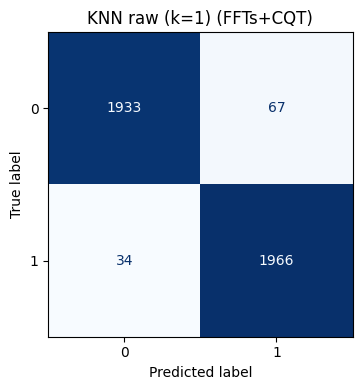

KNN raw (k=1) (FFTs+CQT) - Accuracy: 97.47%
Saved: confusion_matrices\knn_raw_k=1_ffts_cqt.png
  Training time: 0.01s


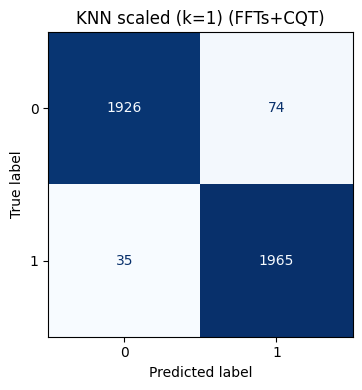

KNN scaled (k=1) (FFTs+CQT) - Accuracy: 97.28%
Saved: confusion_matrices\knn_scaled_k=1_ffts_cqt.png
  Training time: 71.52s


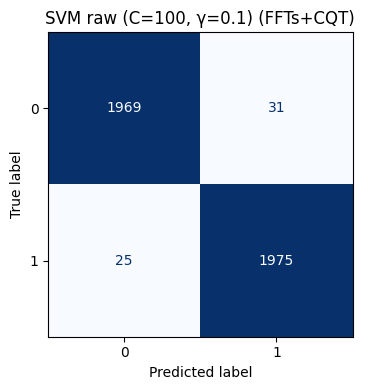

SVM raw (C=100, γ=0.1) (FFTs+CQT) - Accuracy: 98.60%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_ffts_cqt.png
  Training time: 130.19s


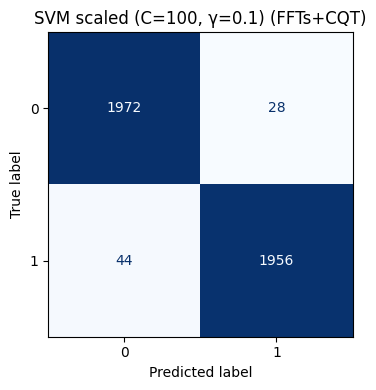

SVM scaled (C=100, γ=0.1) (FFTs+CQT) - Accuracy: 98.20%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_ffts_cqt.png
  Training time: 9.06s


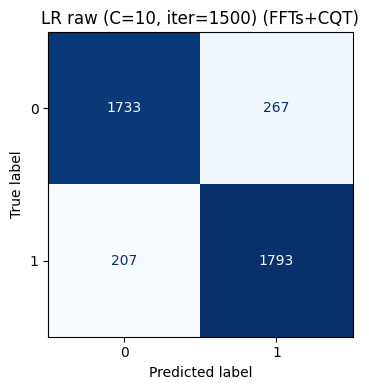

LR raw (C=10, iter=1500) (FFTs+CQT) - Accuracy: 88.15%
Saved: confusion_matrices\lr_raw_c=10_iter=1500_ffts_cqt.png
  Training time: 53.80s


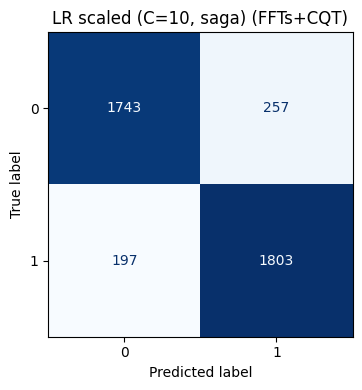

LR scaled (C=10, saga) (FFTs+CQT) - Accuracy: 88.65%
Saved: confusion_matrices\lr_scaled_c=10_saga_ffts_cqt.png
  Training time: 31.06s


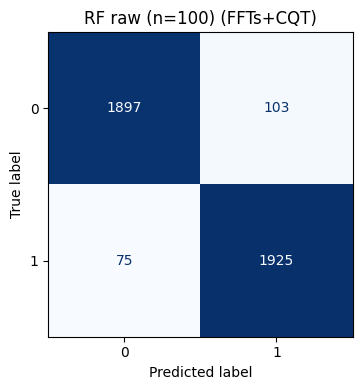

RF raw (n=100) (FFTs+CQT) - Accuracy: 95.55%
Saved: confusion_matrices\rf_raw_n=100_ffts_cqt.png
  Training time: 16.22s


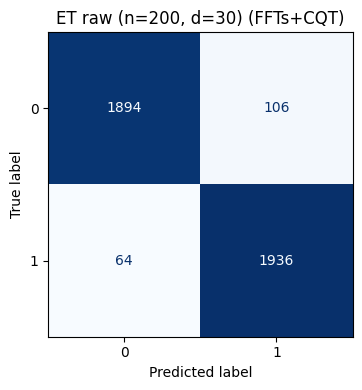

ET raw (n=200, d=30) (FFTs+CQT) - Accuracy: 95.75%
Saved: confusion_matrices\et_raw_n=200_d=30_ffts_cqt.png
  Training time: 16.01s


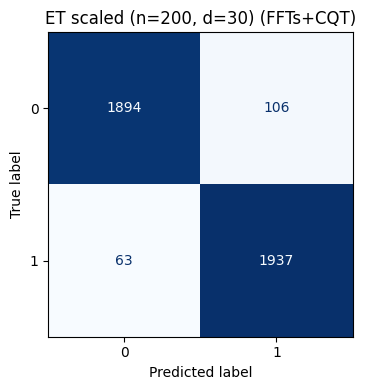

ET scaled (n=200, d=30) (FFTs+CQT) - Accuracy: 95.78%
Saved: confusion_matrices\et_scaled_n=200_d=30_ffts_cqt.png


(0.95775,
 array(['NonQueen', 'NonQueen', 'NonQueen', ..., 'Queen', 'Queen', 'Queen'],
       dtype='<U8'))

In [30]:
print("=== FFTs + CQT ===")

# KNN raw (k=1) — dataset1 uses k=1
train_and_evaluate(KNeighborsClassifier(n_neighbors=1),
                   combined_train, combined_train_labels, combined_test, combined_test_labels,
                   "KNN raw (k=1)", "FFTs+CQT")

# KNN scaled (k=1)
train_and_evaluate(KNeighborsClassifier(n_neighbors=1),
                   combined_train_scaled, combined_train_labels, combined_test_scaled, combined_test_labels,
                   "KNN scaled (k=1)", "FFTs+CQT")

# SVM raw (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   combined_train, combined_train_labels, combined_test, combined_test_labels,
                   "SVM raw (C=100, γ=0.1)", "FFTs+CQT")

# SVM scaled (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   combined_train_scaled, combined_train_labels, combined_test_scaled, combined_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "FFTs+CQT")

# LR raw (C=10, iter=1500) — dataset1 only
train_and_evaluate(LogisticRegression(C=10, max_iter=1500, solver='lbfgs', random_state=42),
                   combined_train, combined_train_labels, combined_test, combined_test_labels,
                   "LR raw (C=10, iter=1500)", "FFTs+CQT")

# LR scaled (C=10, iter=1000, solver=saga) — dataset1 only
train_and_evaluate(LogisticRegression(C=10, max_iter=1000, solver='saga', random_state=42),
                   combined_train_scaled, combined_train_labels, combined_test_scaled, combined_test_labels,
                   "LR scaled (C=10, saga)", "FFTs+CQT")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   combined_train, combined_train_labels, combined_test, combined_test_labels,
                   "RF raw (n=100)", "FFTs+CQT")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   combined_train, combined_train_labels, combined_test, combined_test_labels,
                   "ET raw (n=200, d=30)", "FFTs+CQT")

# ET scaled (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   combined_train_scaled, combined_train_labels, combined_test_scaled, combined_test_labels,
                   "ET scaled (n=200, d=30)", "FFTs+CQT")

# 10. PCA (FFTs + CQT)

In [31]:
# --- Separate FFT and CQT from the combined features, then apply PCA ---

def separate_fft_cqt(combined_features, nfft=512, n_bins=96):
    """Split combined feature vector into FFT and CQT parts."""
    fft_dim = nfft // 2 + 1   # 257 for NFFT=512
    if combined_features.ndim == 1:
        return combined_features[:fft_dim], combined_features[fft_dim:]
    return combined_features[:, :fft_dim], combined_features[:, fft_dim:]

# Separate into FFT (257) and CQT (96) parts
pca_train_fft, pca_train_cqt = separate_fft_cqt(combined_train, nfft=512)
pca_test_fft,  pca_test_cqt  = separate_fft_cqt(combined_test,  nfft=512)

print(f"FFT part: {pca_train_fft.shape}, CQT part: {pca_train_cqt.shape}")

# PCA on FFT: 130 components (random_state=53940)
pca_fft = PCA(n_components=130, random_state=53940)
pca_train_fft_reduced = pca_fft.fit_transform(pca_train_fft)
pca_test_fft_reduced  = pca_fft.transform(pca_test_fft)

# PCA on CQT: 80 components (random_state=53940) — dataset1 applies PCA on CQT too
pca_cqt = PCA(n_components=80, random_state=53940)
pca_train_cqt_reduced = pca_cqt.fit_transform(pca_train_cqt)
pca_test_cqt_reduced  = pca_cqt.transform(pca_test_cqt)

# Recombine: 130 + 80 = 210 features
pca_train_combined = np.hstack((pca_train_fft_reduced, pca_train_cqt_reduced))
pca_test_combined  = np.hstack((pca_test_fft_reduced,  pca_test_cqt_reduced))

print(f"PCA combined: Train {pca_train_combined.shape}, Test {pca_test_combined.shape}")

FFT part: (16076, 257), CQT part: (16076, 96)
PCA combined: Train (16076, 210), Test (4000, 210)


=== PCA (FFTs + CQT) — 210 features ===
  Training time: 13.93s


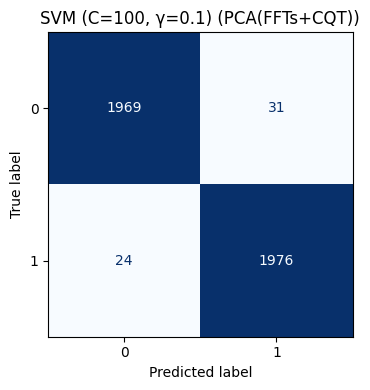

SVM (C=100, γ=0.1) (PCA(FFTs+CQT)) - Accuracy: 98.62%
Saved: confusion_matrices\svm_c=100_γ=0.1_pcaffts_cqt.png


(0.98625,
 array(['NonQueen', 'NonQueen', 'NonQueen', ..., 'Queen', 'Queen', 'Queen'],
       dtype='<U8'))

In [32]:
print("=== PCA (FFTs + CQT) — 210 features ===")

# SVM (C=100, γ=0.1, cache=500) — using PCA features
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, cache_size=500, random_state=42),
                   pca_train_combined, combined_train_labels,
                   pca_test_combined,  combined_test_labels,
                   "SVM (C=100, γ=0.1)", "PCA(FFTs+CQT)")

# 11. PCA (FFTs + CQTs + STFT)

In [33]:
# --- Re-load STFT and apply PCA, then combine with PCA(FFTs+CQT) ---

# Re-load STFT features (may already be in memory, but re-load for completeness)
pca_stft_train, _ = load_stft_features_from_directory(train_path, n_fft=4096, hop_length=1024,
                                                      output_dir=output_dir, dataset_type='train')
pca_stft_val, _   = load_stft_features_from_directory(val_path,   n_fft=4096, hop_length=1024,
                                                      output_dir=output_dir, dataset_type='val')
pca_stft_test, _  = load_stft_features_from_directory(test_path,  n_fft=4096, hop_length=1024,
                                                      output_dir=output_dir, dataset_type='test')

pca_stft_train = np.vstack((pca_stft_train, pca_stft_val))

# PCA on STFT: 80 components (random_state=3951)
pca_stft = PCA(n_components=80, random_state=3951)
pca_stft_train_reduced = pca_stft.fit_transform(pca_stft_train)
pca_stft_test_reduced  = pca_stft.transform(pca_stft_test)

print(f"STFT PCA: Train {pca_stft_train_reduced.shape}, Test {pca_stft_test_reduced.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
STFT PCA: Train (16076, 80), Test (4000, 80)


In [34]:
# Combine: PCA(FFTs+CQT) [210] + PCA(STFT) [80] = 290 features
final_train = np.hstack((pca_train_combined, pca_stft_train_reduced))
final_test  = np.hstack((pca_test_combined,  pca_stft_test_reduced))

print(f"Final combined: Train {final_train.shape}, Test {final_test.shape}")

Final combined: Train (16076, 290), Test (4000, 290)


=== PCA (FFTs + CQTs + STFT) — 290 features ===
  Training time: 9.08s


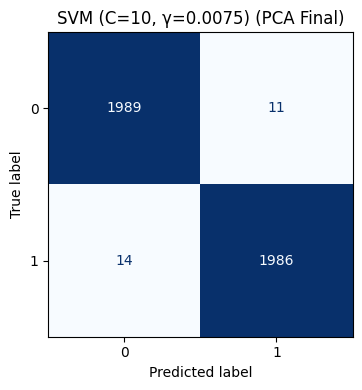

SVM (C=10, γ=0.0075) (PCA Final) - Accuracy: 99.38%
Saved: confusion_matrices\svm_c=10_γ=0.0075_pca_final.png

--- RF with feature selection ---
  RF (n=100)                       | Acc: 97.65% | Time: 4.55s
  RF (top 82 features)             | Acc: 97.92%
  Training time: 1.89s


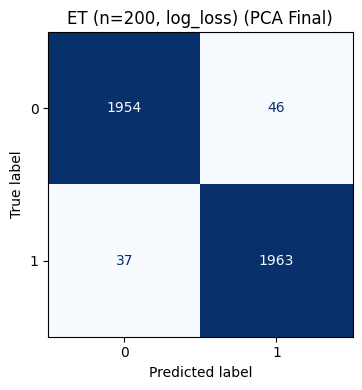

ET (n=200, log_loss) (PCA Final) - Accuracy: 97.92%
Saved: confusion_matrices\et_n=200_log_loss_pca_final.png


(0.97925,
 array(['NonQueen', 'NonQueen', 'NonQueen', ..., 'Queen', 'Queen', 'Queen'],
       dtype='<U8'))

In [35]:
print("=== PCA (FFTs + CQTs + STFT) — 290 features ===")

# SVM (C=10, γ=0.0075, cache=500) — dataset1 specific params
train_and_evaluate(SVC(C=10, kernel='rbf', gamma=0.0075, cache_size=500, random_state=42),
                   final_train, combined_train_labels,
                   final_test,  combined_test_labels,
                   "SVM (C=10, γ=0.0075)", "PCA Final")

# RF (n=100, n_jobs=-1) + feature selection
print("\n--- RF with feature selection ---")
start = time.time()
rf_final = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf_final.fit(final_train, combined_train_labels)
rf_preds = rf_final.predict(final_test)
rf_acc = accuracy_score(combined_test_labels, rf_preds)
print(f"  RF (n=100)                       | Acc: {rf_acc*100:.2f}% | Time: {time.time()-start:.2f}s")

# RF feature selection: top 82 features
importances = rf_final.feature_importances_
top_idx = np.argsort(importances)[::-1][:82]
rf_final.fit(final_train[:, top_idx], combined_train_labels)
rf_sel_preds = rf_final.predict(final_test[:, top_idx])
rf_sel_acc = accuracy_score(combined_test_labels, rf_sel_preds)
print(f"  RF (top 82 features)             | Acc: {rf_sel_acc*100:.2f}%")

# ET (n=200, criterion='log_loss') — dataset1 specific: uses log_loss!
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, criterion='log_loss',
                                        n_jobs=-1, random_state=42),
                   final_train, combined_train_labels,
                   final_test,  combined_test_labels,
                   "ET (n=200, log_loss)", "PCA Final")

# 12. PCA (FFTs + CQTs + STFT) — Reload & No random_state

Loading FFTs features...
  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs - Train shape: (16076, 257), Test shape: (4000, 257)
Loading CQTs features...
  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
CQTs - Train shape: (16076, 84), Test shape: (4000, 84)
Loading STFT features...
  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
STFT - Train shape: (16076, 2049), Test shape: (4000, 2049)
Applying PCA...
FFTs PCA - Train shape: (16076, 130), Test shape: (4000, 130)
CQTs PCA - Train shape: (16076, 80), Test shape: (4000, 80)
STFT PCA - Train shape: (16076, 80), Test shape: (4000, 80)
Combining features...
Combined features - Train shape: (16076, 290)
Combined features - Test shape: (4000, 290)
Training and evaluating multiple models...
  Training time: 9.44s


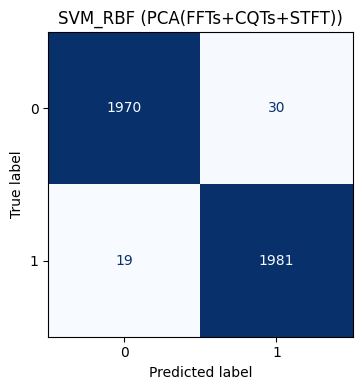

SVM_RBF (PCA(FFTs+CQTs+STFT)) - Accuracy: 98.78%
Saved: confusion_matrices\svm_rbf_pcaffts_cqts_stft.png
  Training time: 0.02s


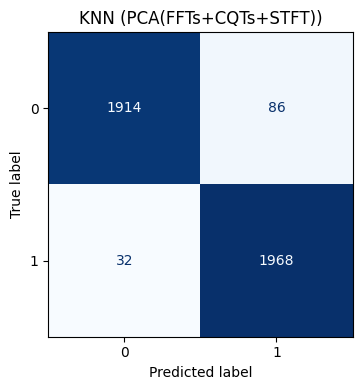

KNN (PCA(FFTs+CQTs+STFT)) - Accuracy: 97.05%
Saved: confusion_matrices\knn_pcaffts_cqts_stft.png
  Training time: 16.75s


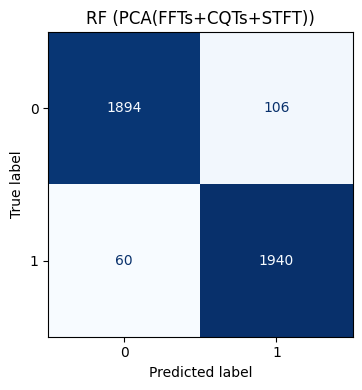

RF (PCA(FFTs+CQTs+STFT)) - Accuracy: 95.85%
Saved: confusion_matrices\rf_pcaffts_cqts_stft.png
  Training time: 5.08s


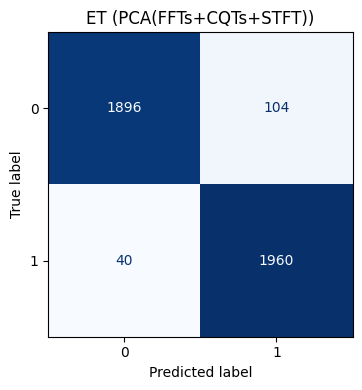

ET (PCA(FFTs+CQTs+STFT)) - Accuracy: 96.40%
Saved: confusion_matrices\et_pcaffts_cqts_stft.png


In [36]:
# =============================================================================
# KẾT HỢP FFTs + CQTs + STFT VÀ TRAIN SVM VỚI THAM SỐ TỐI ƯU
# =============================================================================

# 1. LOAD FFTs FEATURES
print("=" * 60)
print("Loading FFTs features...")
train_features_fft, train_labels_fft = load_fft_features_from_directory(
    train_path, sample_rate=22050, NFFT=512,
    output_dir=output_dir, dataset_type='train'
)
val_features_fft, val_labels_fft = load_fft_features_from_directory(
    val_path, sample_rate=22050, NFFT=512,
    output_dir=output_dir, dataset_type='val'
)
test_features_fft, test_labels_fft = load_fft_features_from_directory(
    test_path, sample_rate=22050, NFFT=512,
    output_dir=output_dir, dataset_type='test'
)

train_features_fft = np.vstack((train_features_fft, val_features_fft))
train_labels_fft = np.hstack((train_labels_fft, val_labels_fft))
print(f"FFTs - Train shape: {train_features_fft.shape}, Test shape: {test_features_fft.shape}")

# 2. LOAD CQTs FEATURES
print("=" * 60)
print("Loading CQTs features...")
cqts_train_features2, cqts_train_labels2 = load_cqts_features_from_directory(
    train_path, sample_rate=22050, frame_size=0.025, frame_stride=0.01,
    fmin=None, n_bins=84, bins_per_octave=12,
    output_dir=output_dir, dataset_type='train'
)
cqts_val_features2, cqts_val_labels2 = load_cqts_features_from_directory(
    val_path, sample_rate=22050, frame_size=0.025, frame_stride=0.01,
    fmin=None, n_bins=84, bins_per_octave=12,
    output_dir=output_dir, dataset_type='val'
)
cqts_test_features2, cqts_test_labels2 = load_cqts_features_from_directory(
    test_path, sample_rate=22050, frame_size=0.025, frame_stride=0.01,
    fmin=None, n_bins=84, bins_per_octave=12,
    output_dir=output_dir, dataset_type='test'
)

cqts_train_features2 = np.vstack((cqts_train_features2, cqts_val_features2))
cqts_train_labels2 = np.hstack((cqts_train_labels2, cqts_val_labels2))
print(f"CQTs - Train shape: {cqts_train_features2.shape}, Test shape: {cqts_test_features2.shape}")

# 3. LOAD STFT FEATURES
print("=" * 60)
print("Loading STFT features...")
stft_train_features2, stft_train_labels2 = load_stft_features_from_directory(
    train_path, sample_rate=22050, n_fft=4096, hop_length=1024,
    output_dir=output_dir, dataset_type='train'
)
stft_val_features2, stft_val_labels2 = load_stft_features_from_directory(
    val_path, sample_rate=22050, n_fft=4096, hop_length=1024,
    output_dir=output_dir, dataset_type='val'
)
stft_test_features2, stft_test_labels2 = load_stft_features_from_directory(
    test_path, sample_rate=22050, n_fft=4096, hop_length=1024,
    output_dir=output_dir, dataset_type='test'
)

stft_train_features2 = np.vstack((stft_train_features2, stft_val_features2))
stft_train_labels2 = np.hstack((stft_train_labels2, stft_val_labels2))
print(f"STFT - Train shape: {stft_train_features2.shape}, Test shape: {stft_test_features2.shape}")

# 4. ÁP DỤNG PCA CHO MỖI LOẠI FEATURES (NO random_state)
print("=" * 60)
print("Applying PCA...")

def apply_pca_to_features(train_features, test_features, n_components=100, plot=False):
    """Áp dụng PCA để giảm số chiều của features (NO random_state)."""
    pca = PCA(n_components=n_components)
    train_pca = pca.fit_transform(train_features)
    test_pca = pca.transform(test_features) if test_features is not None else None

    if plot:
        explained_variance_ratio = pca.explained_variance_ratio_
        cumulative_variance_ratio = np.cumsum(explained_variance_ratio)
        plt.figure(figsize=(10, 6))
        plt.plot(cumulative_variance_ratio, marker='o')
        plt.axhline(y=0.95, color='r', linestyle='-')
        plt.grid(True)
        plt.title('Cumulative Explained Variance Ratio')
        plt.xlabel('Number of Components')
        plt.ylabel('Explained Variance Ratio')
        plt.show()
        n_components_95 = np.where(cumulative_variance_ratio >= 0.95)[0][0] + 1
        print(f"Number of components needed to explain 95% variance: {n_components_95}")
    return train_pca, test_pca, pca

# PCA cho FFTs: 130 components
train_ffts_pca, test_ffts_pca, fft_pca2 = apply_pca_to_features(
    train_features_fft, test_features_fft, n_components=130, plot=False
)
print(f"FFTs PCA - Train shape: {train_ffts_pca.shape}, Test shape: {test_ffts_pca.shape}")

# PCA cho CQTs: 80 components
train_cqts_pca, test_cqts_pca, cqts_pca2 = apply_pca_to_features(
    cqts_train_features2, cqts_test_features2, n_components=80, plot=False
)
print(f"CQTs PCA - Train shape: {train_cqts_pca.shape}, Test shape: {test_cqts_pca.shape}")

# PCA cho STFT: 80 components
train_stft_pca2, test_stft_pca2, stft_pca2 = apply_pca_to_features(
    stft_train_features2, stft_test_features2, n_components=80, plot=False
)
print(f"STFT PCA - Train shape: {train_stft_pca2.shape}, Test shape: {test_stft_pca2.shape}")

# 5. KẾT HỢP TẤT CẢ FEATURES
print("=" * 60)
print("Combining features...")

# FFTs + CQTs
train_features_combined2 = np.hstack((train_ffts_pca, train_cqts_pca))
test_features_combined2 = np.hstack((test_ffts_pca, test_cqts_pca))

# + STFT
combined_train_features2 = np.hstack((train_features_combined2, train_stft_pca2))
combined_test_features2 = np.hstack((test_features_combined2, test_stft_pca2))

print(f"Combined features - Train shape: {combined_train_features2.shape}")
print(f"Combined features - Test shape: {combined_test_features2.shape}")

# 6. TRAIN VỚI CÁC MÔ HÌNH
print("=" * 60)
print("Training and evaluating multiple models...")

models_pca2 = {
    "SVM_RBF": SVC(C=10, kernel='rbf', gamma=0.0075, cache_size=500, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', metric='minkowski', p=2),
    "RF": RandomForestClassifier(n_estimators=400, max_depth=None, n_jobs=-1, random_state=42),
    "ET": ExtraTreesClassifier(n_estimators=600, max_depth=None, n_jobs=-1, random_state=42),
}

for name, clf in models_pca2.items():
    train_and_evaluate(clf, combined_train_features2, train_labels_fft,
                       combined_test_features2, test_labels_fft,
                       f"{name}", "PCA(FFTs+CQTs+STFT)")

# 13. FFTs + CQTs + STFT (Raw & Scaled)

Combining FFTs + CQTs + STFT for Dataset 1...
Combined features shape (train): (16076, 2390)
Combined features shape (test): (4000, 2390)

--------------------------------------------------
Training on NON-SCALED (Raw) Data
--------------------------------------------------
  Training time: 0.09s


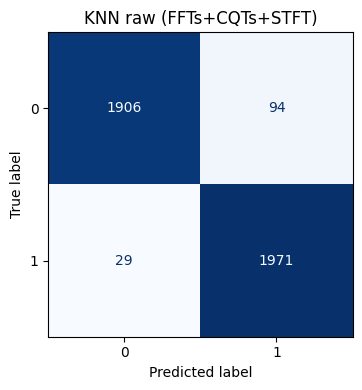

KNN raw (FFTs+CQTs+STFT) - Accuracy: 96.92%
Saved: confusion_matrices\knn_raw_ffts_cqts_stft.png
  Training time: 120.86s


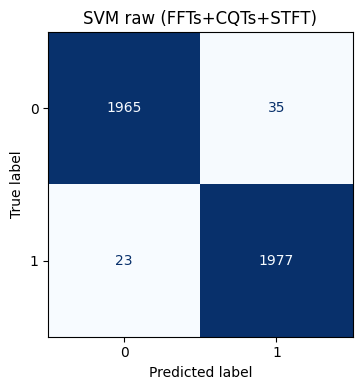

SVM raw (FFTs+CQTs+STFT) - Accuracy: 98.55%
Saved: confusion_matrices\svm_raw_ffts_cqts_stft.png
  Training time: 49.76s


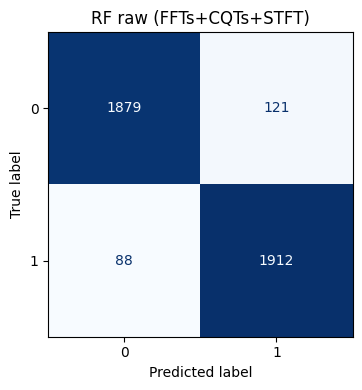

RF raw (FFTs+CQTs+STFT) - Accuracy: 94.77%
Saved: confusion_matrices\rf_raw_ffts_cqts_stft.png
  Training time: 26.99s


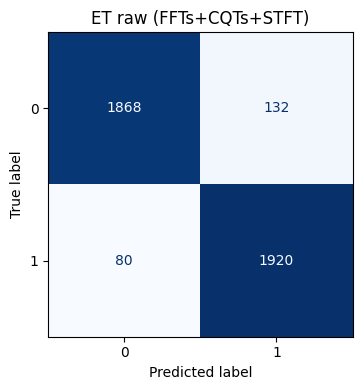

ET raw (FFTs+CQTs+STFT) - Accuracy: 94.70%
Saved: confusion_matrices\et_raw_ffts_cqts_stft.png

Applying StandardScaler...

--------------------------------------------------
Training on SCALED Data
--------------------------------------------------
  Training time: 0.10s


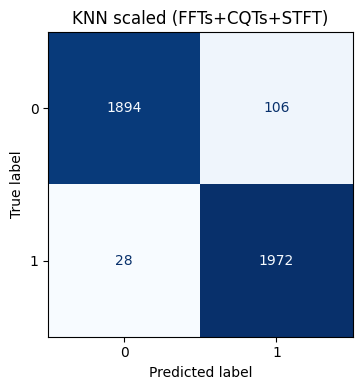

KNN scaled (FFTs+CQTs+STFT) - Accuracy: 96.65%
Saved: confusion_matrices\knn_scaled_ffts_cqts_stft.png
  Training time: 286.62s


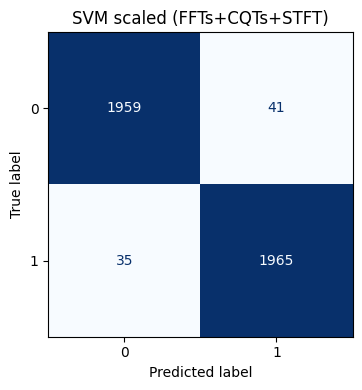

SVM scaled (FFTs+CQTs+STFT) - Accuracy: 98.10%
Saved: confusion_matrices\svm_scaled_ffts_cqts_stft.png
  Training time: 48.83s


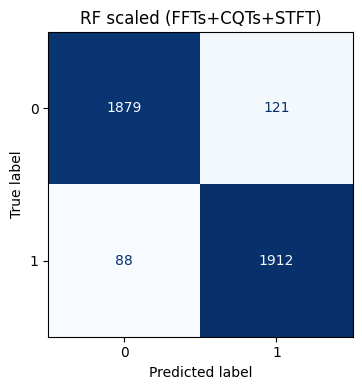

RF scaled (FFTs+CQTs+STFT) - Accuracy: 94.77%
Saved: confusion_matrices\rf_scaled_ffts_cqts_stft.png
  Training time: 28.29s


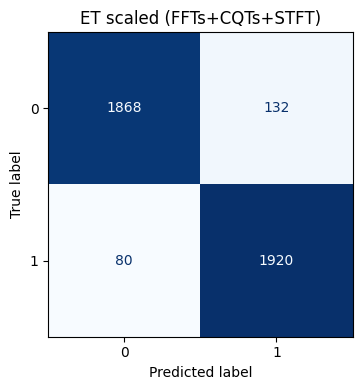

ET scaled (FFTs+CQTs+STFT) - Accuracy: 94.70%
Saved: confusion_matrices\et_scaled_ffts_cqts_stft.png


In [37]:
# =============================================================================
# DATASET 1: FFTs + CQTs + STFT (Raw và Scaled)
# =============================================================================
# Uses: train_features_fft, cqts_train_features2, stft_train_features2 from Section 12

print("="*60)
print("Combining FFTs + CQTs + STFT for Dataset 1...")
print("="*60)

# 1. Kết hợp các đặc trưng (features)
combined_train_D1_A = np.hstack((
    train_features_fft,    # (16076, 257)
    cqts_train_features2,  # (16076, 84)
    stft_train_features2   # (16076, 2049)
))

combined_test_D1_A = np.hstack((
    test_features_fft,     # (4000, 257)
    cqts_test_features2,   # (4000, 84)
    stft_test_features2    # (4000, 2049)
))

print(f"Combined features shape (train): {combined_train_D1_A.shape}")
print(f"Combined features shape (test): {combined_test_D1_A.shape}")

# 2. Định nghĩa các models
models_d1_A = {
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', p=2),
    "SVM": SVC(C=10, kernel='rbf', gamma=0.0075, random_state=42, cache_size=500),
    "RF": RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=42),
    "ET": ExtraTreesClassifier(n_estimators=600, n_jobs=-1, random_state=42)
}

# 3. Huấn luyện trên dữ liệu GỐC (Non-scaled)
print("\n" + "-" * 50)
print("Training on NON-SCALED (Raw) Data")
print("-" * 50)

for name, clf in models_d1_A.items():
    train_and_evaluate(clf, combined_train_D1_A, train_labels_fft,
                       combined_test_D1_A, test_labels_fft,
                       f"{name} raw", "FFTs+CQTs+STFT")

# 4. Chuẩn hóa dữ liệu với StandardScaler
print("\n" + "="*60)
print("Applying StandardScaler...")
print("="*60)

scaler_d1_A = StandardScaler()
scaled_train_D1_A = scaler_d1_A.fit_transform(combined_train_D1_A)
scaled_test_D1_A = scaler_d1_A.transform(combined_test_D1_A)

# 5. Huấn luyện trên dữ liệu ĐÃ CHUẨN HÓA (Scaled)
print("\n" + "-" * 50)
print("Training on SCALED Data")
print("-" * 50)

for name, clf in models_d1_A.items():
    train_and_evaluate(clf, scaled_train_D1_A, train_labels_fft,
                       scaled_test_D1_A, test_labels_fft,
                       f"{name} scaled", "FFTs+CQTs+STFT")

# 14. FFTs + CQT + STFT (Raw & Scaled)

Combining FFTs + CQT + STFT for Dataset 1...
Combined features shape (train): (16076, 2390)
Combined features shape (test): (4000, 2390)

--------------------------------------------------
Training on NON-SCALED (Raw) Data
--------------------------------------------------
  Training time: 0.07s


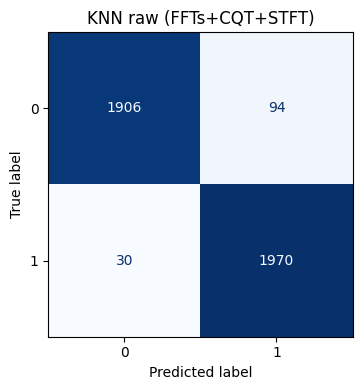

KNN raw (FFTs+CQT+STFT) - Accuracy: 96.90%
Saved: confusion_matrices\knn_raw_ffts_cqt_stft.png
  Training time: 102.85s


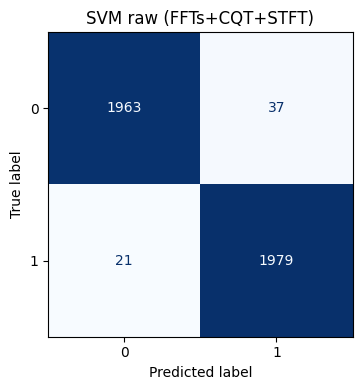

SVM raw (FFTs+CQT+STFT) - Accuracy: 98.55%
Saved: confusion_matrices\svm_raw_ffts_cqt_stft.png
  Training time: 56.25s


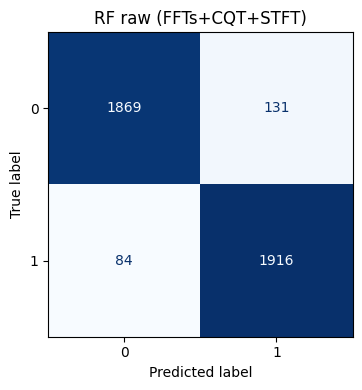

RF raw (FFTs+CQT+STFT) - Accuracy: 94.62%
Saved: confusion_matrices\rf_raw_ffts_cqt_stft.png
  Training time: 23.27s


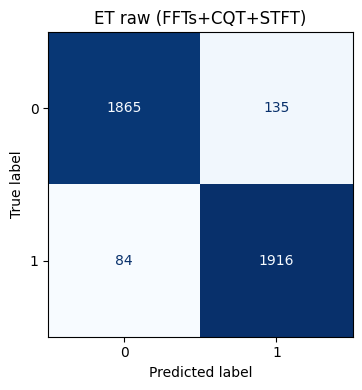

ET raw (FFTs+CQT+STFT) - Accuracy: 94.53%
Saved: confusion_matrices\et_raw_ffts_cqt_stft.png

Applying StandardScaler...

--------------------------------------------------
Training on SCALED Data
--------------------------------------------------
  Training time: 0.07s


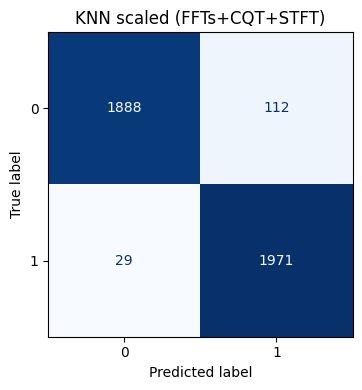

KNN scaled (FFTs+CQT+STFT) - Accuracy: 96.47%
Saved: confusion_matrices\knn_scaled_ffts_cqt_stft.png
  Training time: 277.00s


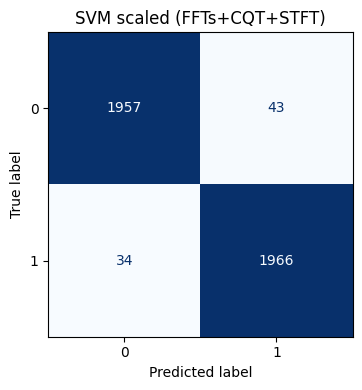

SVM scaled (FFTs+CQT+STFT) - Accuracy: 98.08%
Saved: confusion_matrices\svm_scaled_ffts_cqt_stft.png
  Training time: 48.19s


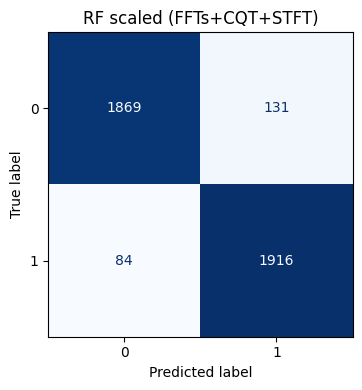

RF scaled (FFTs+CQT+STFT) - Accuracy: 94.62%
Saved: confusion_matrices\rf_scaled_ffts_cqt_stft.png
  Training time: 21.98s


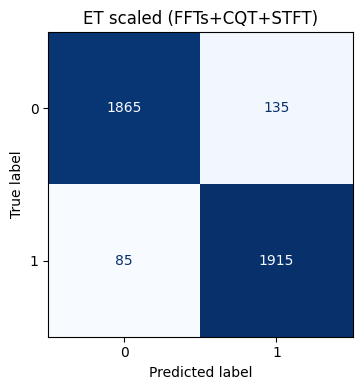

ET scaled (FFTs+CQT+STFT) - Accuracy: 94.50%
Saved: confusion_matrices\et_scaled_ffts_cqt_stft.png


In [38]:
# =============================================================================
# DATASET 1: FFTs + CQT + STFT (Raw và Scaled)
# Uses: train_features_fft (FFTs), cqt_train (standalone CQT), stft_train (STFT librosa)
# =============================================================================

print("="*60)
print("Combining FFTs + CQT + STFT for Dataset 1...")
print("="*60)

# 1. Kết hợp các đặc trưng: FFTs (257) + CQT (84) + STFT (2049) = 2390
combined_train_D1_B = np.hstack((
    train_features_fft,  # from Section 12 FFTs reload
    cqt_train,           # from Section 7 standalone CQT (84 dims)
    stft_train           # from Section 3 STFT (2049 dims)
))

combined_test_D1_B = np.hstack((
    test_features_fft,
    cqt_test,
    stft_test
))

print(f"Combined features shape (train): {combined_train_D1_B.shape}")
print(f"Combined features shape (test): {combined_test_D1_B.shape}")

# 2. Định nghĩa các models
models_d1_B = {
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', p=2),
    "SVM": SVC(C=10, kernel='rbf', gamma=0.0075, random_state=42, cache_size=500),
    "RF": RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=42),
    "ET": ExtraTreesClassifier(n_estimators=600, n_jobs=-1, random_state=42)
}

# 3. Huấn luyện trên dữ liệu GỐC (Non-scaled)
print("\n" + "-" * 50)
print("Training on NON-SCALED (Raw) Data")
print("-" * 50)

for name, clf in models_d1_B.items():
    train_and_evaluate(clf, combined_train_D1_B, train_labels_fft,
                       combined_test_D1_B, test_labels_fft,
                       f"{name} raw", "FFTs+CQT+STFT")

# 4. Chuẩn hóa dữ liệu với StandardScaler
print("\n" + "="*60)
print("Applying StandardScaler...")
print("="*60)

scaler_d1_B = StandardScaler()
scaled_train_D1_B = scaler_d1_B.fit_transform(combined_train_D1_B)
scaled_test_D1_B = scaler_d1_B.transform(combined_test_D1_B)

# 5. Huấn luyện trên dữ liệu ĐÃ CHUẨN HÓA (Scaled)
print("\n" + "-" * 50)
print("Training on SCALED Data")
print("-" * 50)

for name, clf in models_d1_B.items():
    train_and_evaluate(clf, scaled_train_D1_B, train_labels_fft,
                       scaled_test_D1_B, test_labels_fft,
                       f"{name} scaled", "FFTs+CQT+STFT")